# CALCE CS2: audited feature engineering and selection

This notebook executes the raw-data reconstruction, checks representative cells, builds conservative measured SOH labels, selects charging features using training batteries, and displays executed results. Original raw files and previous preprocessing outputs are preserved.

**Prediction timing:** current-cycle estimation uses measurements through the end of charging; forecasting uses charging features from an earlier observed episode. No target discharge feature enters the predictors. Partial cycles are kept without invented labels.

Select the project `.venv` Python interpreter in VS Code. All research outputs go to `CS2/cs2_feature_research`. See the generated audit and protocol for limitations; in particular unresolved CADEX clocks and cross-workbook continuity require further work.

In [1]:
from pathlib import Path
import sys, json, logging
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
PROJECT = Path.cwd()
if not (PROJECT / 'cs2_research_pipeline.py').exists():
    PROJECT = PROJECT / 'Battery_SOH_Diverse'
assert (PROJECT / 'cs2_research_pipeline.py').exists(), 'Run from Battery_SOH_Diverse or its parent'
sys.path.insert(0, str(PROJECT))
from cs2_research_pipeline import OUT, CONFIG, battery_id, extract
from cs2_research_analysis import analyze, FEATURES
OUT.mkdir(parents=True, exist_ok=True)
logging.basicConfig(filename=str(OUT/'pipeline.log'), level=logging.INFO)
print('Python:', sys.executable)
print('Outputs:', OUT)
assert battery_id(Path('CS2_3/CS2_3_1_1_10.xlsx')) == 'CS2_3'
assert battery_id(Path('CS2_33/CS2_33_1_1_10.xlsx')) == 'CS2_33'
assert battery_id(Path('CS2_38/CS2_38_1_1_10.xlsx')) == 'CS2_38'


C:\Projects\Battery_SOH_Diverse\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: C:\Projects\Battery_SOH_Diverse\.venv\Scripts\python.exe
Outputs: C:\Projects\Battery_SOH_Diverse\CS2\cs2_feature_research


## Representative reconstruction gate

Inspect full-cycling CS2_33/34, variable-rate CS2_3 and partial-cycling CS2_5 before processing all sources. Discharge episodes replace the exported cycle index as the reconstruction unit.

In [2]:
representative, representative_inventory = extract(representative=True)
display(representative.groupby('battery').agg(episodes=('battery','size'), labels=('soh','count')))
display(representative.groupby(['battery','reason']).size().rename('count').reset_index())
assert set(representative.battery) == {'CS2_33','CS2_34','CS2_3','CS2_5'}
assert representative.loc[representative.label_valid, 'discharge_end_v'].le(CONFIG['full_discharge_end_v']).all()
assert representative.loc[~representative.label_valid, 'soh'].isna().all()
assert representative.loc[representative.label_valid, 'capacity_relative_disagreement'].dropna().le(.03).all()


Raw files:   0%|          | 0/4 [00:00<?, ?it/s]

Raw files: 100%|██████████| 4/4 [00:00<00:00, 248.52it/s]

FILES 4 BATTERIES 4 EPISODES 223 LABELS 112


,episodes,labels
battery,,
CS2_3,60,52
CS2_33,23,21
CS2_34,39,38
CS2_5,101,1


,battery,reason,count
0,CS2_3,insufficient_discharge_points,8
1,CS2_3,validated,52
2,CS2_33,no_verified_full_charge_before_discharge,1
3,CS2_33,partial_discharge_or_missing_cutoff,1
4,CS2_33,validated,21
5,CS2_34,no_verified_full_charge_before_discharge,1
6,CS2_34,validated,38
7,CS2_5,no_verified_full_charge_before_discharge,99
8,CS2_5,partial_discharge_or_missing_cutoff;no_verifie...,1
9,CS2_5,validated,1


## Full extraction with resume

Each file has a content-configuration checkpoint. Re-running resumes completed files. CADEX logs are accepted only when their two recorded clocks independently agree; unresolved logs stay in manual review.

In [3]:
data, inventory = extract()
print('Discovered batteries:', inventory.battery.nunique())
print('Extracted episodes:', len(data))
print('Validated labels:', data.soh.notna().sum())
display(data.groupby('battery').agg(episodes=('cycle_id','size'), validated_labels=('soh','count')))


Raw files:   0%|          | 0/606 [00:00<?, ?it/s]

Raw files: 100%|██████████| 606/606 [00:02<00:00, 243.75it/s]

FILES 606 BATTERIES 15 EPISODES 35851 LABELS 7793


Discovered batteries: 15
Extracted episodes: 35851
Validated labels: 7793


,episodes,validated_labels
battery,,
CS2_21,362,12
CS2_24,5039,53
CS2_25,6695,70
CS2_3,1919,1164
CS2_33,866,833
CS2_34,776,758
CS2_35,882,854
CS2_36,974,944
CS2_37,1038,1007


## Verify forecast continuity from raw evidence

Long intervals qualify as rest only when measured current and operating-step clocks support that interpretation. Forecast windows also require consecutive reconstructed episode indices within the same workbook.

In [4]:
from cs2_continuity import audit_continuity
continuity = audit_continuity(data)
display(continuity.continuity_reason.value_counts().to_frame('episode_boundaries'))

Verify raw episode boundaries:   0%|          | 0/573 [00:00<?, ?it/s]

Verify raw episode boundaries: 100%|██████████| 573/573 [00:01<00:00, 400.59it/s]

Verified episode boundaries: 34460


,episode_boundaries
continuity_reason,
verified_rest_samples_and_step_clock,34460
first_or_missing_charge,1075
unknown_interval_or_intervening_active_samples,313


## Training-only statistics and feature selection

Eligibility, mRMR screening and sequential forward selection use training batteries. Outer battery-held-out evaluations redo feature selection. Ridge and HGB compare selected, all-eligible and charging-baseline inputs. Forecasting and estimation use separate output tables.

In [5]:
# Cached models remain valid only while raw sources and core implementation match.
import hashlib
from cs2_research_pipeline import source_snapshot_sha256
from cs2_research_analysis import prepare_observations
data = prepare_observations(data)
RECOMPUTE_ANALYSIS = False
cached = json.loads((OUT/'dataset_manifest.json').read_text()) if (OUT/'dataset_manifest.json').exists() else {}
stale = cached.get('source_snapshot_sha256') != source_snapshot_sha256()
for filename in ['cs2_research_pipeline.py','cs2_research_analysis.py','cs2_continuity.py']:
    stale |= cached.get('implementation_sha256',{}).get(filename) != hashlib.sha256((PROJECT/filename).read_bytes()).hexdigest()
analysis_recomputed = RECOMPUTE_ANALYSIS or stale
if analysis_recomputed:
    manifest = analyze(data, inventory)
else:
    manifest = cached
display(pd.read_csv(OUT/'top_5_features.csv'))
print(json.dumps(manifest, indent=2))

,rank,feature,selection,generalization_status
0,1,cc_throughput_ah,training-only mRMR shortlist + inner battery-h...,provisional: did not beat charging/persistence...
1,2,throughput_bracket_3p9_4p1_ah,training-only mRMR shortlist + inner battery-h...,provisional: did not beat charging/persistence...
2,3,cc_voltage_increase_v,training-only mRMR shortlist + inner battery-h...,provisional: did not beat charging/persistence...
3,4,cc_voltage_slope_v_s,training-only mRMR shortlist + inner battery-h...,provisional: did not beat charging/persistence...
4,5,charge_voltage_mean_v,training-only mRMR shortlist + inner battery-h...,provisional: did not beat charging/persistence...


{
  "implementation_sha256": {
    "cs2_research_pipeline.py": "2ba00905fe9c22514ecb62aa7287545cdfe599f38378bb11248051acd9cf95fe",
    "cs2_research_analysis.py": "8d12cc5ef5b769e2830e6df728e7b83b79cad1272ebec2ccde385f71784c9e89",
    "cs2_continuity.py": "97e5ee9d8ac9a410d05c96f8252386988e2724992ed26c11aa5f7897d0b4c1a6",
    "cs2_statistics.py": "647d910c742fc062274ca23338c33915efdff15e7290640c51b17098a8ea6900",
    "cs2_acquisition_robustness.py": "6351ea40f5c54082e6c48de61a508b9268fea57725b9136bd28f541108853943",
    "cs2_history_robustness.py": "36195db2b1b5d432809f2d1d9c15193871df03077cd8706ef652ae167f25ecea",
    "cs2_partial_views.py": "59c2c45cd88b8baa57572cb32f101286c6be339a54f8caf9a82459c314242ddb",
    "finalize_cs2_research.py": "bcd642815380b695eb3aa8bbb755dae2d295fb56b20d0e61519f33a1aaf6264c"
  },
  "status": "executed_conservative_pipeline",
  "raw_files": 606,
  "processed_batteries": 15,
  "batteries_with_extracted_episodes": 15,
  "validated_soh_labels": 7793,
  "extr

In [6]:
for filename in ['estimation_battery_macro.csv', 'forecast_pair_counts.csv', 'forecasting_results.csv', 'robustness_results.csv']:
    print(filename)
    p = OUT/filename
    if p.exists():
        table = pd.read_csv(p)
        display(table.head(30))
        if table.empty: print('No supported experiment rows; see protocol and pair counts.')


estimation_battery_macro.csv


,task,horizon,split,model,subset,rmse,mae,r2
0,estimation,0,outer_cv,hgb,all_eligible,0.100860,0.058095,0.343386
1,estimation,0,outer_cv,hgb,charging_baseline,0.148407,0.108725,-2.850511
2,estimation,0,outer_cv,hgb,selected,0.126480,0.088084,-1.619326
3,estimation,0,outer_cv,ridge,all_eligible,0.301925,0.178270,-25.964412
4,estimation,0,outer_cv,ridge,charging_baseline,0.170720,0.147001,-6.042064
5,estimation,0,outer_cv,ridge,selected,0.182112,0.155897,-6.598462
6,estimation,0,test,hgb,all_eligible,0.213675,0.143674,0.593107
7,estimation,0,test,hgb,charging_baseline,0.219477,0.122204,0.570049
8,estimation,0,test,hgb,selected,0.236619,0.182442,0.411220
9,estimation,0,test,ridge,all_eligible,0.508951,0.430140,-3.545553


forecast_pair_counts.csv


,horizon,n_pairs,batteries
0,1,7296,11
1,3,6674,11
2,5,6271,11


forecasting_results.csv


,task,horizon,battery,split,model,subset,rmse,mae,r2,n
0,forecasting,1,CS2_7,test,ridge,selected,0.245026,0.182068,0.172167,94
1,forecasting,1,CS2_7,test,ridge,all_eligible,1.040118,0.947538,-13.917126,94
2,forecasting,1,CS2_7,test,ridge,charging_baseline,0.156146,0.057297,0.663811,94
3,forecasting,1,CS2_7,test,hgb,selected,0.352363,0.295894,-0.711985,94
4,forecasting,1,CS2_7,test,hgb,all_eligible,0.213378,0.200171,0.372201,94
5,forecasting,1,CS2_7,test,hgb,charging_baseline,0.156051,0.053322,0.664221,94
6,forecasting,1,CS2_7,test,persistence_origin_soh,origin_soh_available_after_discharge,0.007001,0.002875,0.999324,94
7,forecasting,1,CS2_9,test,ridge,selected,0.201976,0.157155,0.740031,809
8,forecasting,1,CS2_9,test,ridge,all_eligible,0.208819,0.138734,0.722119,809
9,forecasting,1,CS2_9,test,ridge,charging_baseline,0.179450,0.139350,0.794787,809


robustness_results.csv


,horizon,battery,model,scenario,rmse,mae,r2,n
0,1,CS2_7,ridge,complete,0.215545,0.195483,0.359390,94
1,1,CS2_7,ridge,missing_cc,0.284799,0.281744,-0.118402,94
2,1,CS2_7,ridge,missing_cv,0.222631,0.207143,0.316573,94
3,1,CS2_7,ridge,random_missing,0.240065,0.219068,0.205347,94
4,1,CS2_7,ridge,consecutive_missing_origins,0.221132,0.202786,0.325746,94
5,1,CS2_9,ridge,complete,0.265860,0.195181,0.549570,809
6,1,CS2_9,ridge,missing_cc,0.409082,0.339956,-0.066452,809
7,1,CS2_9,ridge,missing_cv,0.370911,0.260489,0.123282,809
8,1,CS2_9,ridge,random_missing,0.309578,0.229360,0.389253,809
9,1,CS2_9,ridge,consecutive_missing_origins,0.270650,0.206008,0.533193,809


## Raw partial-charge and missing-history diagnostics

Physical partial views are re-extracted from measured prefixes/suffixes, separately from feature masking. Historical dropout removes two complete consecutive observation vectors from a verified four-observation history. These bounded baseline experiments do not establish acquisition invariance.

In [7]:
from cs2_partial_views import run_partial_views
from cs2_acquisition_robustness import run_acquisition_robustness
from cs2_history_robustness import run_history_robustness
from finalize_cs2_research import finalize
RECOMPUTE_ROBUSTNESS = analysis_recomputed
if RECOMPUTE_ROBUSTNESS or not (OUT/'robustness_mask_definition.json').exists():
    run_acquisition_robustness()
if RECOMPUTE_ROBUSTNESS or not (OUT/'physical_partial_observation_manifest.json').exists():
    run_partial_views()
if RECOMPUTE_ROBUSTNESS or not (OUT/'historical_observation_robustness_protocol.json').exists():
    run_history_robustness()
validation_summary = finalize()
for filename in ['physical_partial_observation_battery_macro.csv','historical_observation_robustness_battery_macro.csv']:
    if (OUT/filename).exists():
        print(filename)
        display(pd.read_csv(OUT/filename))

{
  "validated_labels": 7793,
  "unique_batteries": 15,
  "selected_features": [
    "cc_throughput_ah",
    "throughput_bracket_3p9_4p1_ah",
    "cc_voltage_increase_v",
    "cc_voltage_slope_v_s",
    "charge_voltage_mean_v"
  ],
  "all_label_endpoints_pass": true,
  "all_available_counter_crosschecks_pass": true,
  "disjoint_splits": true,
  "forecast_horizon_indices_pass": true,
  "retained_extreme_soh_labels": 569,
  "unresolved_cadex_files": 24,
  "read_error_files": 0
}
physical_partial_observation_battery_macro.csv


,view,model,rmse,mae,r2
0,complete,hgb,0.315669,0.223783,-55523.943563
1,complete,ridge,0.244821,0.185195,-53532.182201
2,prefix_50_percent_samples,hgb,0.313570,0.215349,-54378.246442
3,prefix_50_percent_samples,ridge,0.239948,0.169862,-51118.852932
4,prefix_80_percent_samples,hgb,0.315669,0.223783,-55523.943563
5,prefix_80_percent_samples,ridge,0.243406,0.181165,-52823.459402
6,suffix_50_percent_samples,hgb,0.468252,0.468224,-171442.298741
7,suffix_50_percent_samples,ridge,0.468239,0.468173,-243465.794818


historical_observation_robustness_battery_macro.csv


,horizon,model,scenario,rmse,mae,r2
0,1,hgb,four_observed_history_vectors,0.106423,0.080058,0.823280
1,1,hgb,two_consecutive_history_observations_missing,0.106352,0.080014,0.823322
2,1,ridge,four_observed_history_vectors,0.186098,0.159176,0.477204
3,1,ridge,two_consecutive_history_observations_missing,0.175482,0.146889,0.535090
4,3,hgb,four_observed_history_vectors,0.162319,0.144509,0.699117
5,3,hgb,two_consecutive_history_observations_missing,0.186644,0.163913,0.623721
6,3,ridge,four_observed_history_vectors,0.179485,0.161829,0.582695
7,3,ridge,two_consecutive_history_observations_missing,0.143468,0.129753,0.796402
8,5,hgb,four_observed_history_vectors,0.092589,0.077139,0.860621
9,5,hgb,two_consecutive_history_observations_missing,0.093935,0.078326,0.858865


In [8]:
manifest = json.loads((OUT/'dataset_manifest.json').read_text())
assert set(manifest['train_batteries']).isdisjoint(manifest['test_batteries'])
assert set(manifest['train_batteries']).isdisjoint(manifest['validation_batteries'])
assert len(manifest['selected_features']) == 5 or len(manifest['eligible_features']) < 5
print('Disjoint battery splits verified; label and forecast-index checks:', validation_summary)
display(pd.read_csv(OUT/'cs2_battery_summary.csv'))

Disjoint battery splits verified; label and forecast-index checks: {'validated_labels': 7793, 'unique_batteries': 15, 'selected_features': ['cc_throughput_ah', 'throughput_bracket_3p9_4p1_ah', 'cc_voltage_increase_v', 'cc_voltage_slope_v_s', 'charge_voltage_mean_v'], 'all_label_endpoints_pass': True, 'all_available_counter_crosschecks_pass': True, 'disjoint_splits': True, 'forecast_horizon_indices_pass': True, 'retained_extreme_soh_labels': 569, 'unresolved_cadex_files': 24, 'read_error_files': 0}


,battery,episodes,validated_labels,mean_soh,sources
0,CS2_21,362,12,0.916568,11
1,CS2_24,5039,53,0.817208,53
2,CS2_25,6695,70,0.839163,72
3,CS2_3,1919,1164,0.636645,39
4,CS2_33,866,833,0.767407,23
5,CS2_34,776,758,0.854925,23
6,CS2_35,882,854,0.798579,24
7,CS2_36,974,944,0.743686,26
8,CS2_37,1038,1007,0.752057,27
9,CS2_38,1028,992,0.785237,27


## Visual audit

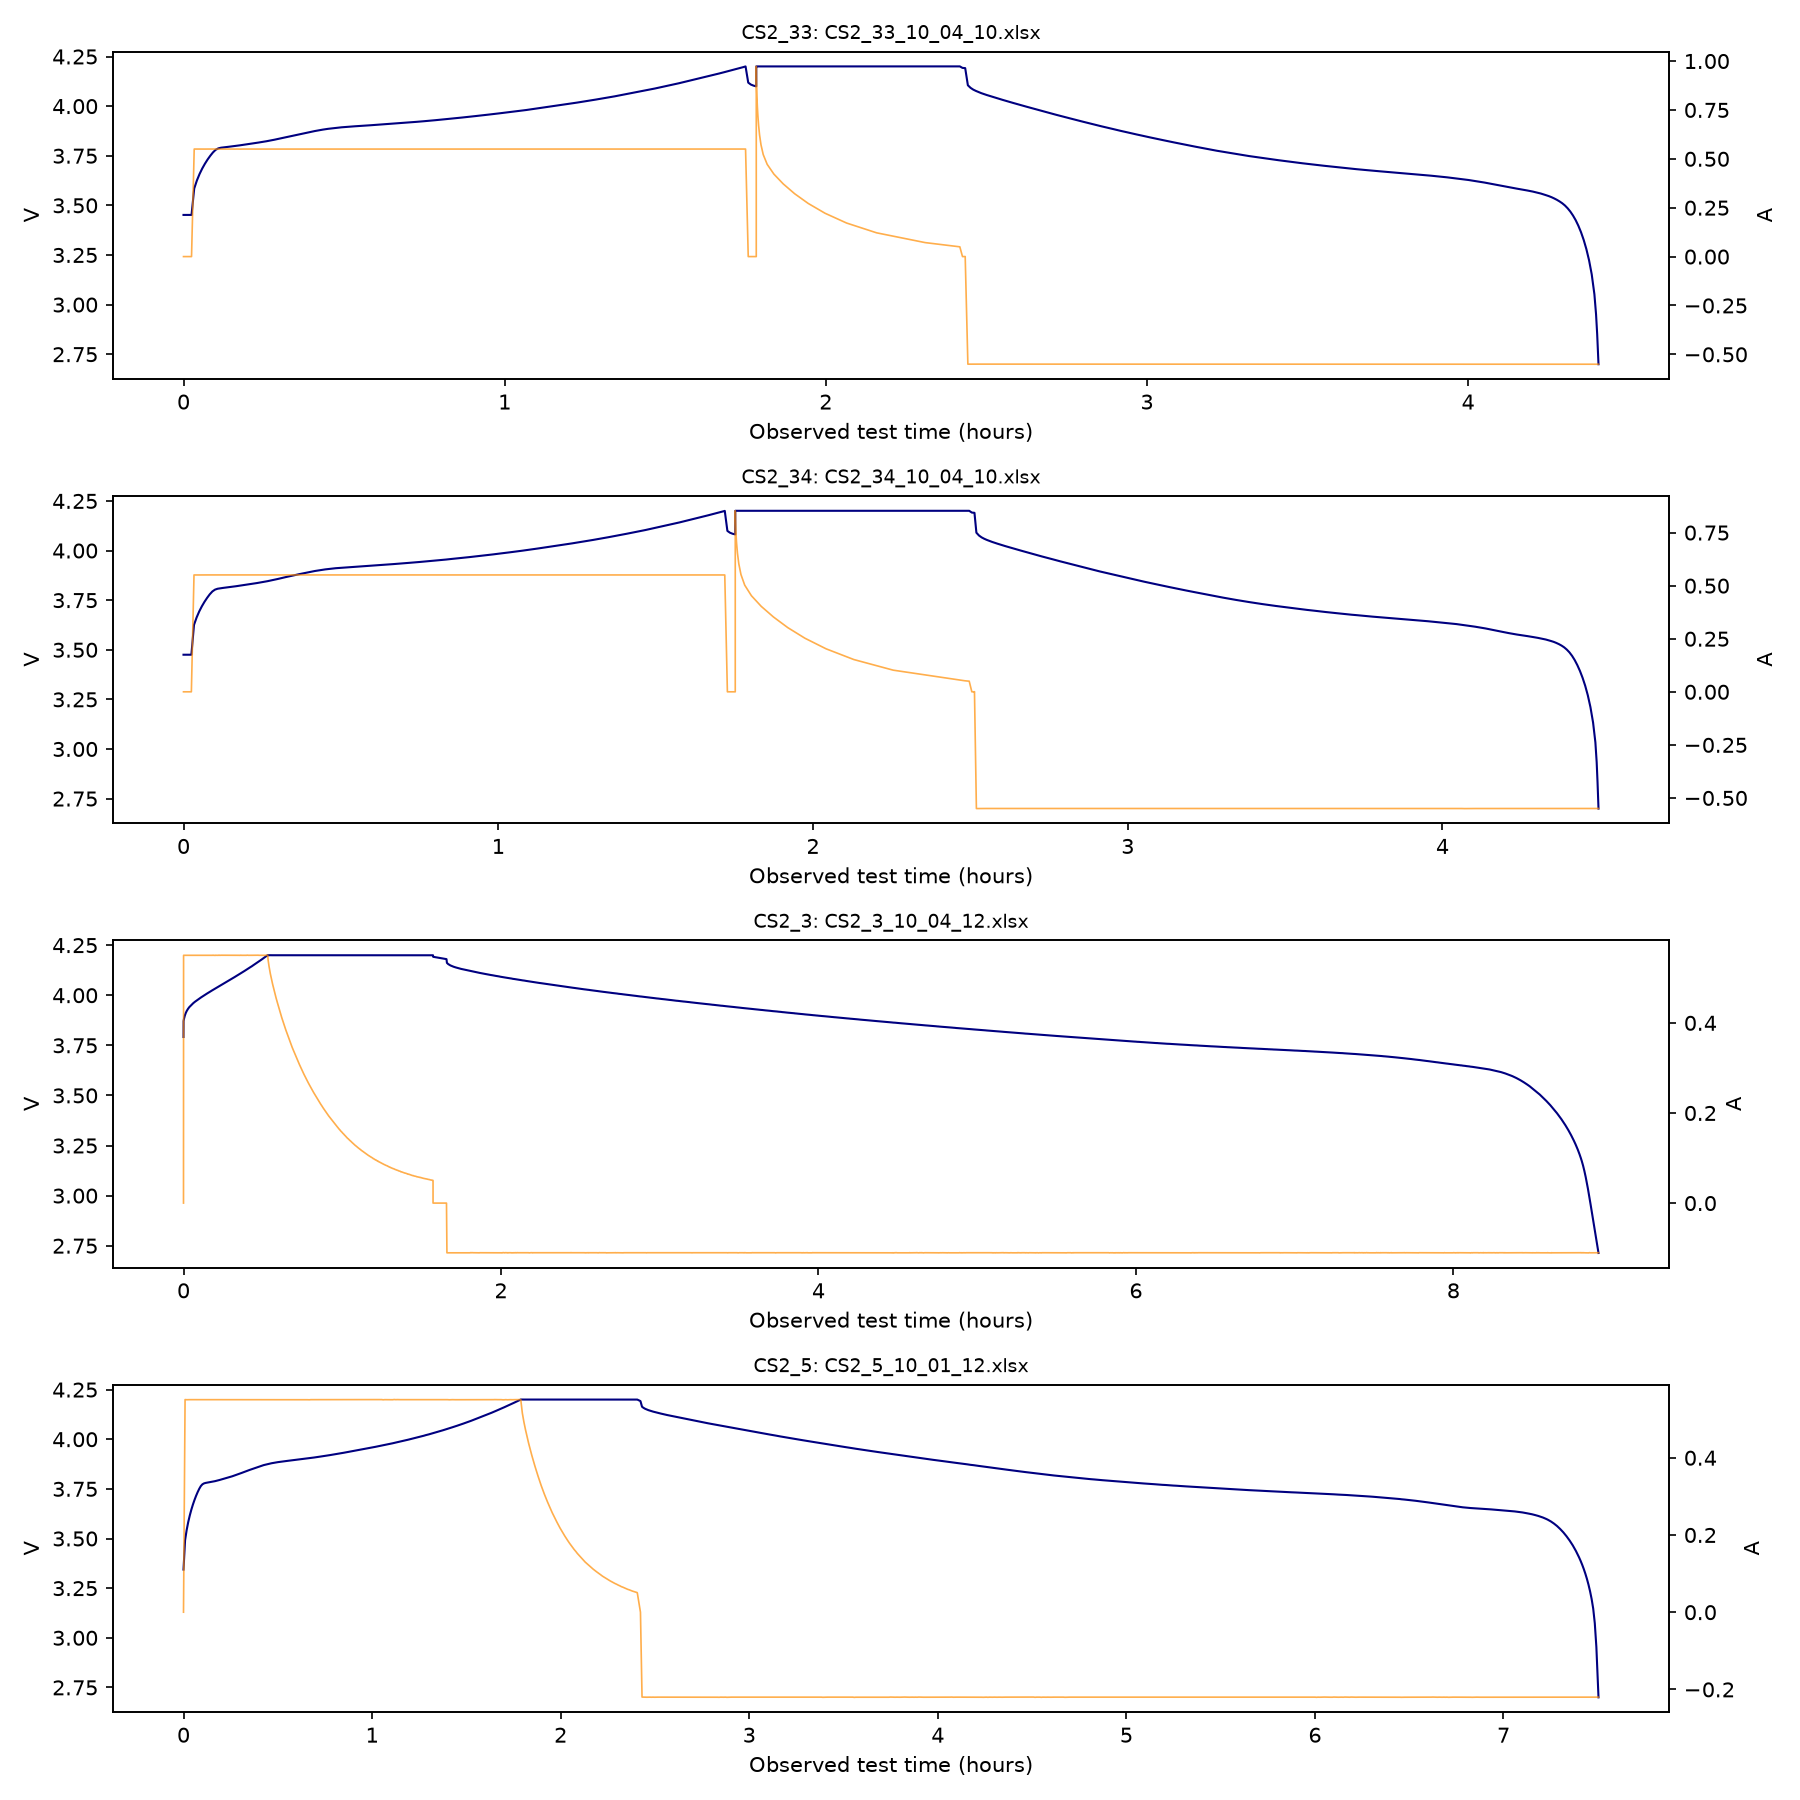

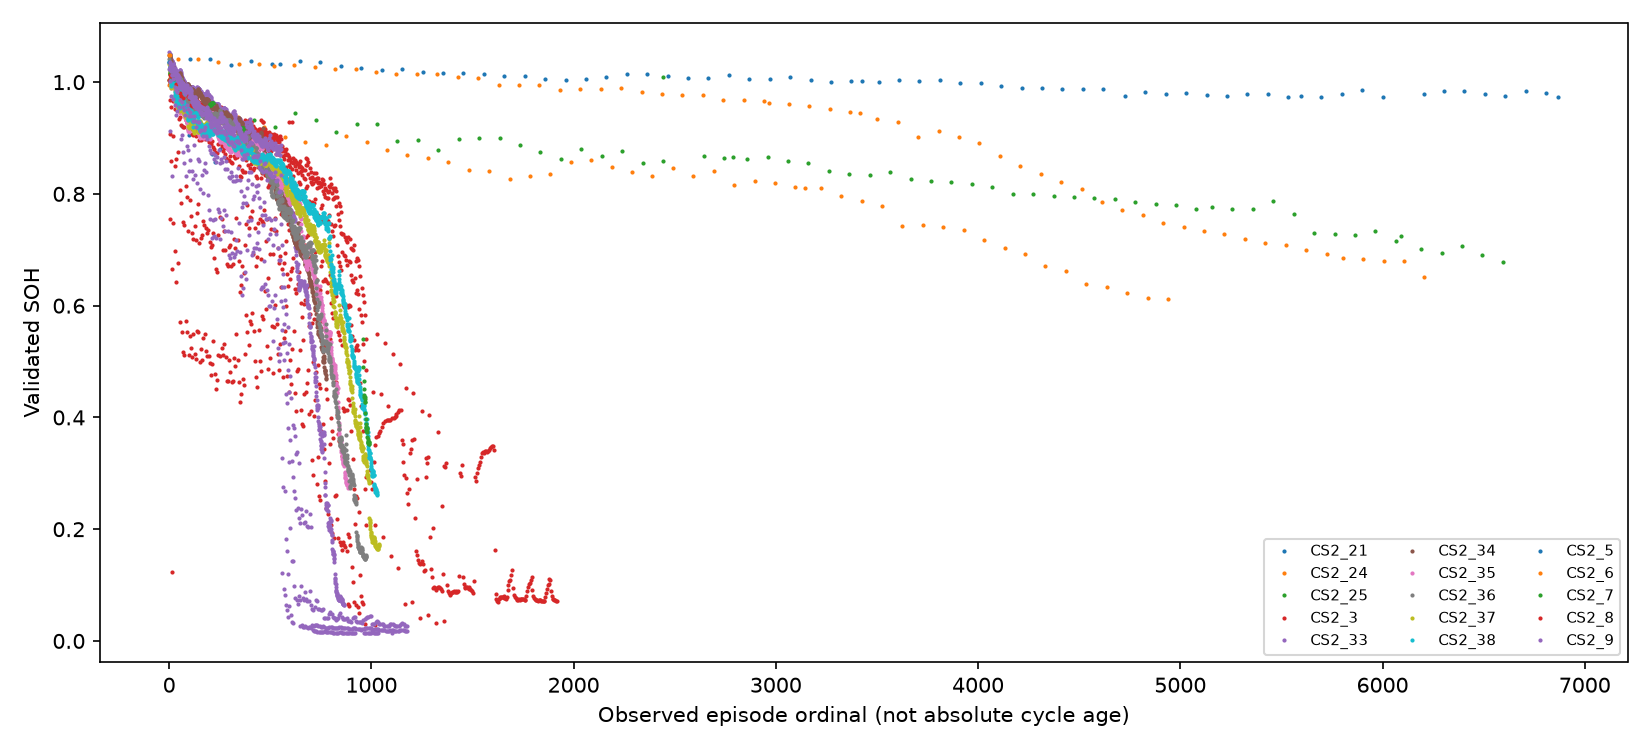

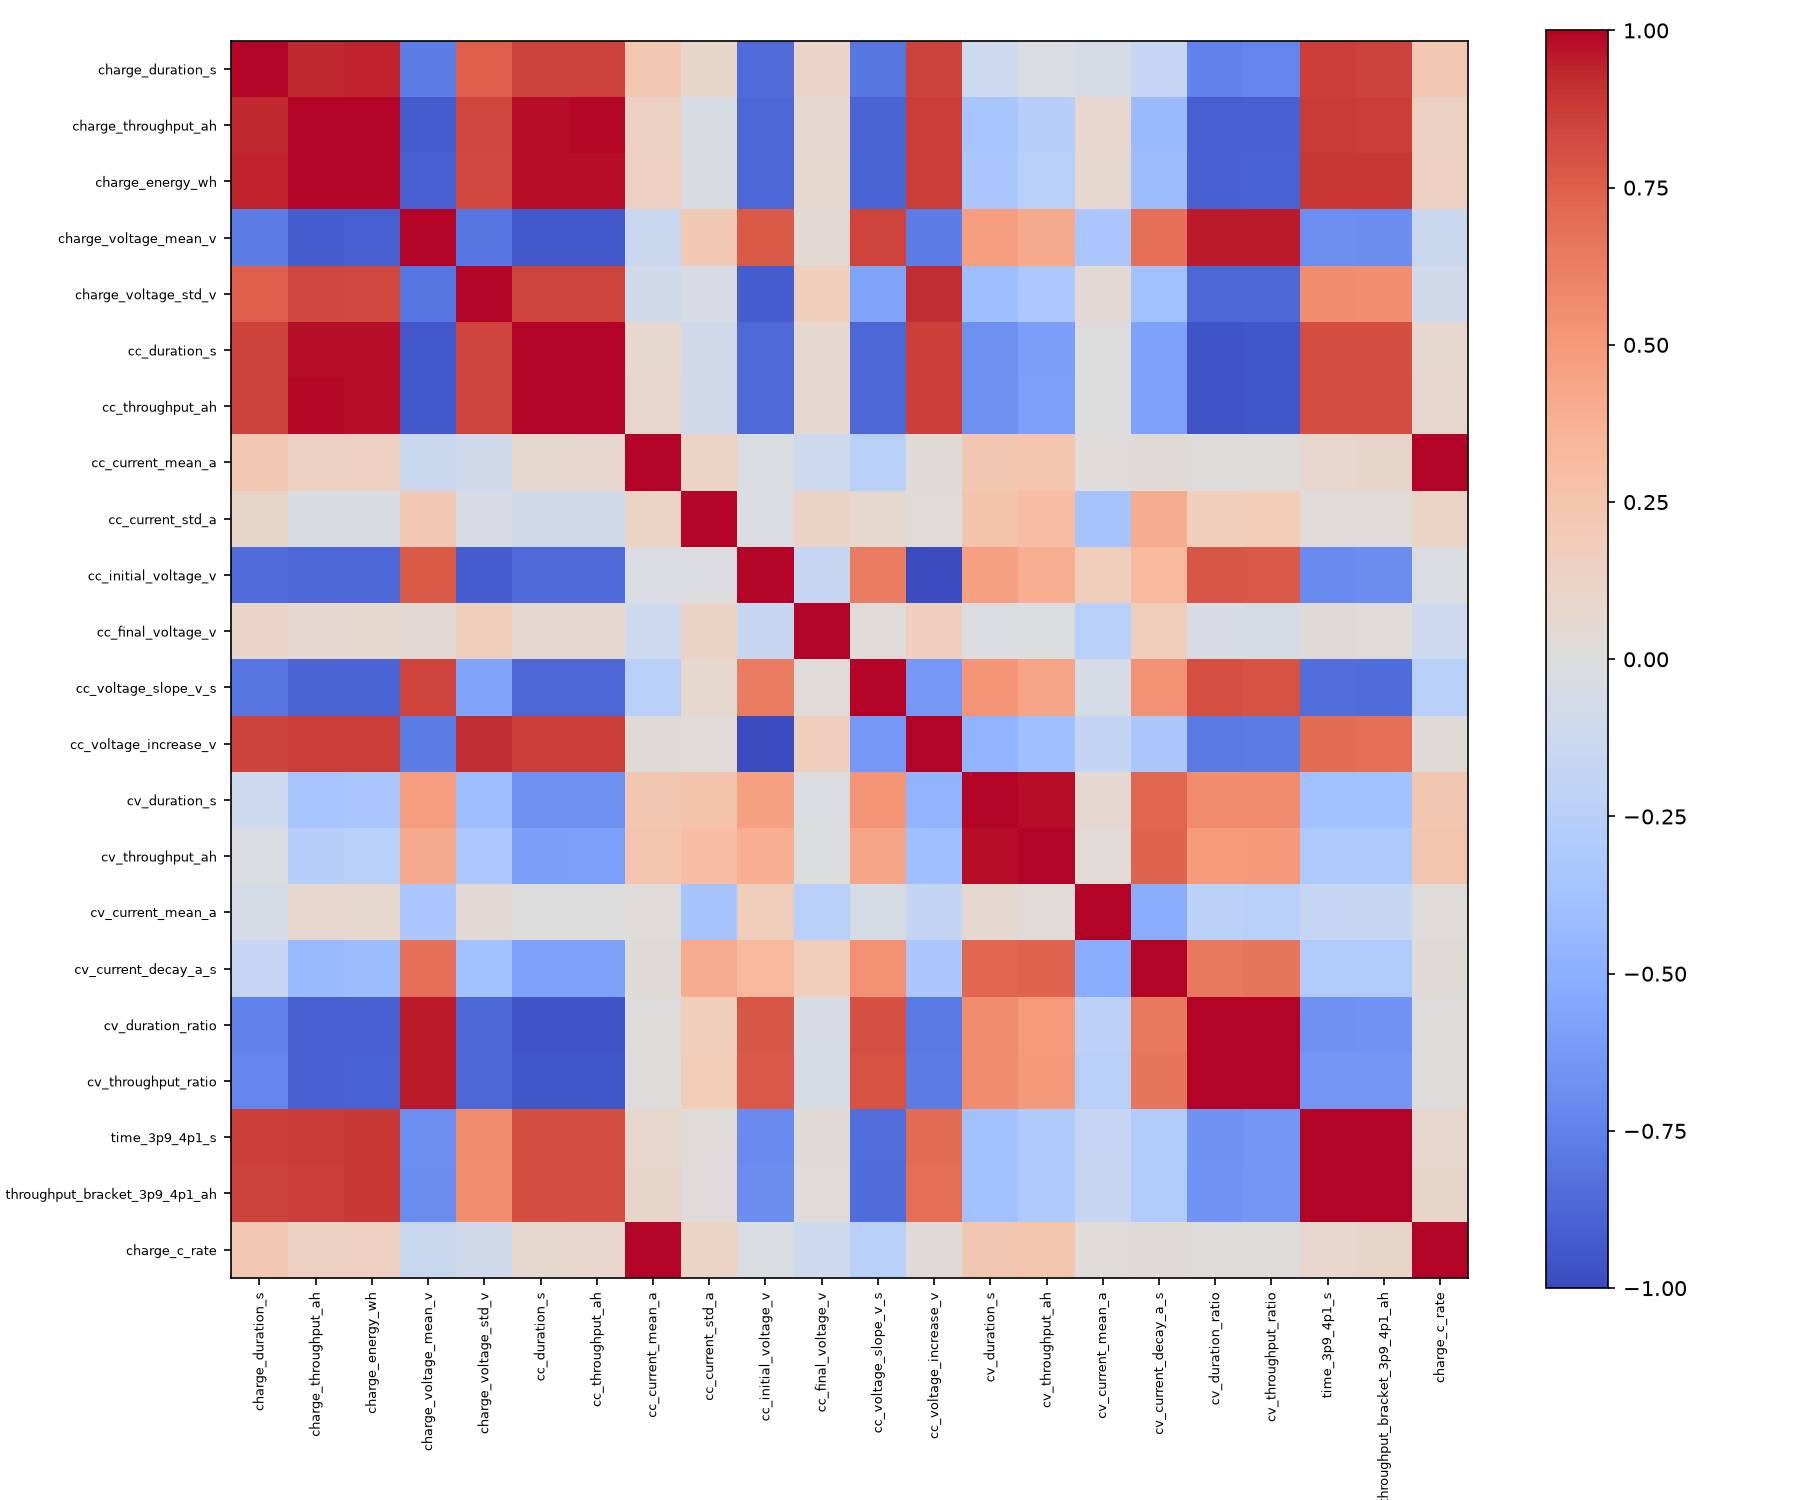

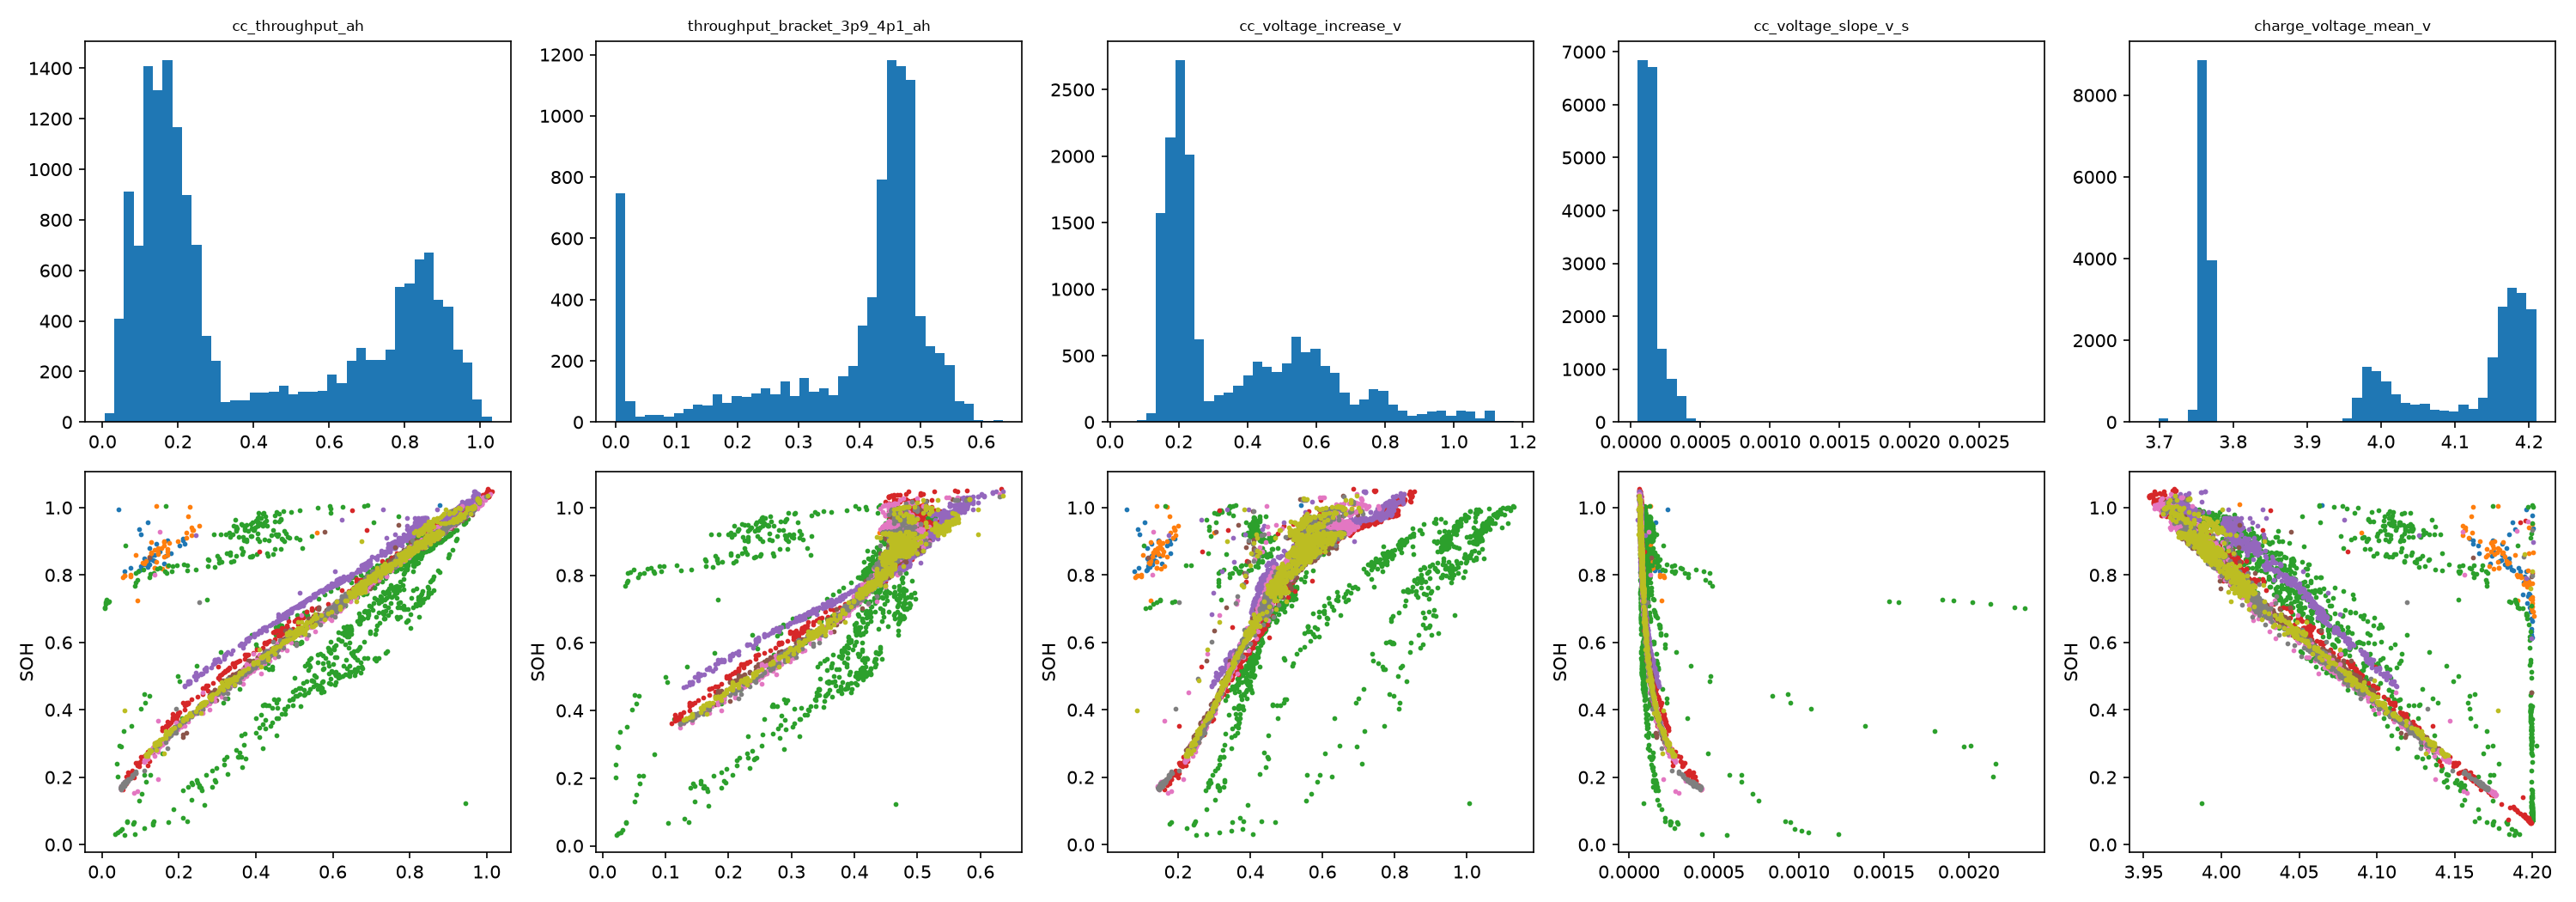

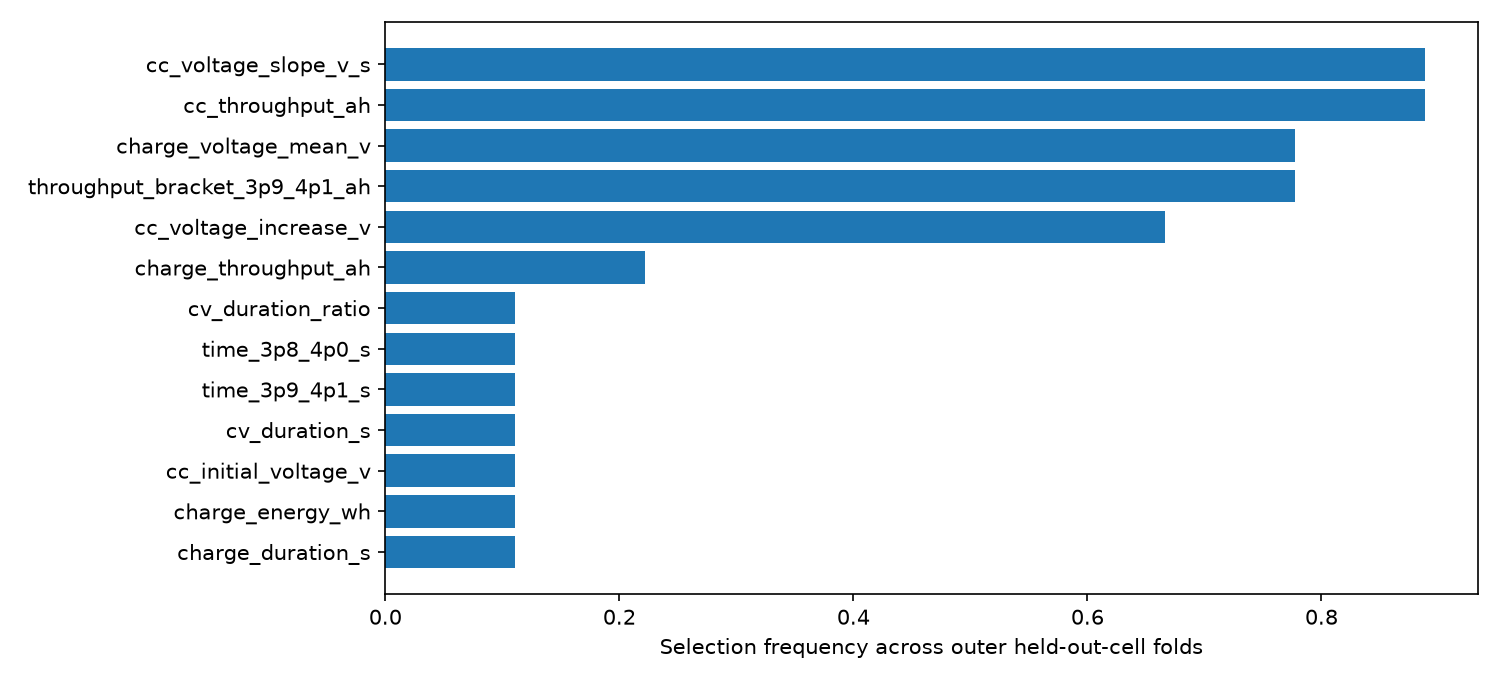

In [9]:
for filename in ['representative_raw_profiles.png','soh_trajectories.png','feature_correlation_heatmap.png','selected_feature_distributions_and_scatter.png','feature_selection_stability.png']:
    p = OUT/filename
    if p.exists(): display(Image(filename=str(p)))


In [10]:
display(Markdown((OUT/'FEATURE_ENGINEERING_REPORT.md').read_text(encoding='utf8')))
print('Generated files:')
for p in sorted(OUT.iterdir()):
    if p.is_file(): print(p.name)


# CALCE CS2 feature research â€” executed results

Processed 606 raw files across 15 discovered batteries. Extracted 35851 discharge episodes, 7793 validated labels and 37 charging feature definitions. Exactly 5 features selected.

## 1. Valid labels per battery
```
battery  episodes  validated_labels  mean_soh  sources
 CS2_21       362                12  0.916568       11
 CS2_24      5039                53  0.817208       53
 CS2_25      6695                70  0.839163       72
  CS2_3      1919              1164  0.636645       39
 CS2_33       866               833  0.767407       23
 CS2_34       776               758  0.854925       23
 CS2_35       882               854  0.798579       24
 CS2_36       974               944  0.743686       26
 CS2_37      1038              1007  0.752057       27
 CS2_38      1028               992  0.785237       27
  CS2_5      6971                71  1.002163       76
  CS2_6      6307                66  0.906152       66
  CS2_7      1119               101  0.801335       48
  CS2_8       693                19  0.954725       20
  CS2_9      1182               849  0.605252       41
```
## 2. Previous pipeline failures
The previous battery parser extracted the first digit run in `CS2_33`, which is `2`, assigning all cells CS2_2. It grouped a full workbook by exported Cycle_Index, even when one index contained repeated operating episodes. It evaluated the fifth percentile of discharge voltage against 2.85 V rather than the observed terminal cutoff: a steep low-voltage tail can be complete while its fifth percentile remains above 2.85 V. It split raw sheets and did not account for cumulative capacity counters. The new pipeline reconstructs contiguous current episodes across channel sheets and preserves partial episodes. These mechanisms are verified from code and raw examples; their individual contribution to all old rejections has not been causally quantified.

## 3. Strongest training-cell associations

Pearson:
```
             feature    n   pearson  pearson_p  spearman  spearman_p   kendall  kendall_p  mutual_information  partial_pearson_age  eligible_current_cycle  pearson_bh_q  spearman_bh_q  kendall_bh_q
    cc_throughput_ah 6308  0.873478        0.0  0.902638         0.0  0.805614        0.0            2.176713             0.674113                    True           0.0            0.0           0.0
       cc_duration_s 6308  0.873276        0.0  0.901653         0.0  0.803939        0.0            2.157040             0.674668                    True           0.0            0.0           0.0
charge_throughput_ah 6675  0.862371        0.0  0.910413         0.0  0.852769        0.0            3.075290             0.603534                    True           0.0            0.0           0.0
    charge_energy_wh 6675  0.860012        0.0  0.909991         0.0  0.848416        0.0            2.939620             0.602288                    True           0.0            0.0           0.0
   cv_duration_ratio 6672 -0.847720        0.0 -0.835776         0.0 -0.684841        0.0            1.524673            -0.627967                    True           0.0            0.0           0.0
```

Spearman:
```
                      feature    n  pearson  pearson_p  spearman  spearman_p  kendall  kendall_p  mutual_information  partial_pearson_age  eligible_current_cycle  pearson_bh_q  spearman_bh_q  kendall_bh_q
         charge_throughput_ah 6675 0.862371        0.0  0.910413         0.0 0.852769        0.0            3.075290             0.603534                    True           0.0            0.0           0.0
             charge_energy_wh 6675 0.860012        0.0  0.909991         0.0 0.848416        0.0            2.939620             0.602288                    True           0.0            0.0           0.0
             cc_throughput_ah 6308 0.873478        0.0  0.902638         0.0 0.805614        0.0            2.176713             0.674113                    True           0.0            0.0           0.0
                cc_duration_s 6308 0.873276        0.0  0.901653         0.0 0.803939        0.0            2.157040             0.674668                    True           0.0            0.0           0.0
throughput_bracket_3p8_4p0_ah 5215 0.808912        0.0  0.880013         0.0 0.764045        0.0            1.786487             0.394109                   False           0.0            0.0           0.0
```

Eligibility flags distinguish exploratory associations from reliable primary predictors.

## 4. Nonlinear dependence estimates

```
             feature    n  pearson  pearson_p  spearman  spearman_p  kendall  kendall_p  mutual_information  partial_pearson_age  eligible_current_cycle  pearson_bh_q  spearman_bh_q  kendall_bh_q
charge_throughput_ah 6675 0.862371        0.0  0.910413         0.0 0.852769        0.0            3.075290             0.603534                    True           0.0            0.0           0.0
    charge_energy_wh 6675 0.860012        0.0  0.909991         0.0 0.848416        0.0            2.939620             0.602288                    True           0.0            0.0           0.0
    cc_throughput_ah 6308 0.873478        0.0  0.902638         0.0 0.805614        0.0            2.176713             0.674113                    True           0.0            0.0           0.0
       cc_duration_s 6308 0.873276        0.0  0.901653         0.0 0.803939        0.0            2.157040             0.674668                    True           0.0            0.0           0.0
      time_3p8_4p0_s 5215 0.807741        0.0  0.877927         0.0 0.765043        0.0            1.859951             0.394349                   False           0.0            0.0           0.0
```

Mutual information measures dependence, not proof of a nonlinear mechanism. P-values/BH q-values remain exploratory because cycles are serially dependent.

## 5. Redundancy
See Pearson and Spearman matrices in feature_redundancy_matrix.csv. Throughput, duration and energy are physically related; mRMR penalizes their redundancy before sequential selection.

## 6. Unseen-cell predictivity
See estimation_results.csv and estimation_battery_macro.csv. Outer folds redo selection on training cells only. Inner folds fit imputation and scaling on their training cells. Selection optimizes the one-cycle forecasting target where sufficient pairs exist and is a Ridge surrogate; HGB is an independent predictive comparison. Metrics use SOH fractions, so multiply errors by 100 for percentage points. Battery-macro means give each cell equal weight.

## 7â€“8. Final selected features and rationale
cc_throughput_ah, throughput_bracket_3p9_4p1_ah, cc_voltage_increase_v, cc_voltage_slope_v_s, charge_voltage_mean_v.
Selection requires >=80% training availability, variation and >=3 supported cells; DVA is excluded as insufficiently validated. A relevance-versus-redundancy shortlist is followed by sequential forward selection to five using inner battery-macro RMSE. Selection task: one_cycle_forecasting. Features with >0.98 absolute Spearman redundancy to an already selected feature are excluded. The unvalidated voltage-time-integral implementation is excluded from published features. Among candidates within 1% (+0.00001 SOH) of the best inner score, final selection prefers the higher outer-fold selection frequency. Thus selection does not follow the highest pooled correlation. See feature_subset_experiments.csv for every executed subset and feature_selection_stability.csv for outer-fold frequency. Availability and feature stability still require external experimental replication.

## 9. Five versus all eligible features
Estimation battery-macro results (SOH fraction units):
```
      task  horizon      split model            subset     rmse      mae         r2
estimation        0   outer_cv   hgb      all_eligible 0.100860 0.058095   0.343386
estimation        0   outer_cv   hgb charging_baseline 0.148407 0.108725  -2.850511
estimation        0   outer_cv   hgb          selected 0.126480 0.088084  -1.619326
estimation        0   outer_cv ridge      all_eligible 0.301925 0.178270 -25.964412
estimation        0   outer_cv ridge charging_baseline 0.170720 0.147001  -6.042064
estimation        0   outer_cv ridge          selected 0.182112 0.155897  -6.598462
estimation        0       test   hgb      all_eligible 0.213675 0.143674   0.593107
estimation        0       test   hgb charging_baseline 0.219477 0.122204   0.570049
estimation        0       test   hgb          selected 0.236619 0.182442   0.411220
estimation        0       test ridge      all_eligible 0.508951 0.430140  -3.545553
estimation        0       test ridge charging_baseline 0.154088 0.084328   0.758366
estimation        0       test ridge          selected 0.210884 0.135285   0.461028
estimation        0 validation   hgb      all_eligible 0.099503 0.076531 -12.663966
estimation        0 validation   hgb charging_baseline 0.086597 0.046425  -9.186311
estimation        0 validation   hgb          selected 0.133791 0.084263 -29.513019
estimation        0 validation ridge      all_eligible 0.154536 0.117494 -45.200993
estimation        0 validation ridge charging_baseline 0.095992 0.058288 -20.630320
estimation        0 validation ridge          selected 0.086753 0.036156 -16.905915
```
See separate selected/all_eligible/charging_baseline rows in estimation_battery_macro.csv and forecasting_results.csv. No pooled-cycle score is presented as independent-cell evidence.

## 10. Forecasting and acquisition robustness

Forecasting battery-macro metrics (SOH fraction):
```
 horizon    split                  model                               subset     rmse      mae        r2
       1 outer_cv                    hgb                         all_eligible 0.108982 0.067899  0.662818
       1 outer_cv                    hgb                    charging_baseline 0.124912 0.081488  0.578392
       1 outer_cv                    hgb                             selected 0.104064 0.069137  0.663458
       1 outer_cv persistence_origin_soh origin_soh_available_after_discharge 0.032294 0.022287  0.888026
       1 outer_cv                  ridge                         all_eligible 0.116961 0.085967  0.595292
       1 outer_cv                  ridge                    charging_baseline 0.103196 0.072920  0.698320
       1 outer_cv                  ridge                             selected 0.113722 0.084470  0.556928
       1     test                    hgb                         all_eligible 0.229738 0.184750  0.493123
       1     test                    hgb                    charging_baseline 0.212190 0.124490  0.602694
       1     test                    hgb                             selected 0.346927 0.266732 -0.227571
       1     test persistence_origin_soh origin_soh_available_after_discharge 0.048560 0.030400  0.970605
       1     test                  ridge                         all_eligible 0.624468 0.543136 -6.597503
       1     test                  ridge                    charging_baseline 0.167798 0.098324  0.729299
       1     test                  ridge                             selected 0.223501 0.169611  0.456099
       3 outer_cv                    hgb                         all_eligible 0.092746 0.056625  0.689773
       3 outer_cv                    hgb                    charging_baseline 0.129934 0.090599  0.194193
       3 outer_cv                    hgb                             selected 0.084251 0.054690  0.712094
       3 outer_cv persistence_origin_soh origin_soh_available_after_discharge 0.050645 0.042970  0.699011
       3 outer_cv                  ridge                         all_eligible 0.103120 0.076693  0.491528
       3 outer_cv                  ridge                    charging_baseline 0.094861 0.067307  0.666518
       3 outer_cv                  ridge                             selected 0.112894 0.088229  0.447225
       3     test                    hgb                         all_eligible 0.267956 0.224449  0.196061
       3     test                    hgb                    charging_baseline 0.176367 0.108912  0.680278
       3     test                    hgb                             selected 0.306483 0.245200 -0.066764
       3     test persistence_origin_soh origin_soh_available_after_discharge 0.091675 0.064968  0.510244
       3     test                  ridge                         all_eligible 0.494324 0.416375 -3.092261
       3     test                  ridge                    charging_baseline 0.173624 0.103734  0.707112
       3     test                  ridge                             selected 0.223861 0.142603  0.421698
       5 outer_cv                    hgb                         all_eligible 0.059536 0.023492  0.907429
       5 outer_cv                    hgb                    charging_baseline 0.052013 0.018857  0.934770
       5 outer_cv                    hgb                             selected 0.051355 0.021072  0.937164
       5 outer_cv persistence_origin_soh origin_soh_available_after_discharge 0.040959 0.029029  0.823663
       5 outer_cv                  ridge                         all_eligible 0.090590 0.058414  0.618610
       5 outer_cv                  ridge                    charging_baseline 0.052326 0.021551  0.928460
       5 outer_cv                  ridge                             selected 0.051745 0.019417  0.936323
       5     test                    hgb                         all_eligible 0.195984 0.112892  0.672229
       5     test                    hgb                    charging_baseline 0.198651 0.091510  0.632169
       5     test                    hgb                             selected 0.238698 0.158579  0.478200
       5     test persistence_origin_soh origin_soh_available_after_discharge 0.059741 0.037765  0.959513
       5     test                  ridge                         all_eligible 0.183767 0.133426  0.545773
       5     test                  ridge                    charging_baseline 0.137819 0.051689  0.722357
       5     test                  ridge                             selected 0.201117 0.148753  0.492022
```

Missingness-aware feature-mask baselines:
```
 horizon model                    scenario     rmse      mae        r2
       1   hgb                    complete 0.270924 0.213083  0.299474
       1   hgb consecutive_missing_origins 0.265735 0.216376  0.338647
       1   hgb                  missing_cc 0.346739 0.308790 -0.088439
       1   hgb                  missing_cv 0.303856 0.243053  0.178005
       1   hgb              random_missing 0.295496 0.234753  0.169184
       1 ridge                    complete 0.240702 0.195332  0.454480
       1 ridge consecutive_missing_origins 0.245891 0.204397  0.429470
       1 ridge                  missing_cc 0.346941 0.310850 -0.092427
       1 ridge                  missing_cv 0.296771 0.233816  0.219928
       1 ridge              random_missing 0.274822 0.224214  0.297300
       3   hgb                    complete 0.283475 0.236004  0.055599
       3   hgb consecutive_missing_origins 0.258305 0.213356  0.270068
       3   hgb                  missing_cc 0.354741 0.297734 -0.105102
       3   hgb                  missing_cv 0.393844 0.332905 -0.443660
       3   hgb              random_missing 0.320835 0.267755 -0.095107
       3 ridge                    complete 0.304010 0.262250  0.071609
       3 ridge consecutive_missing_origins 0.288451 0.247696  0.196800
       3 ridge                  missing_cc 0.352175 0.301054 -0.091884
       3 ridge                  missing_cv 0.361861 0.298147 -0.186530
       3 ridge              random_missing 0.328281 0.280691 -0.043610
       5   hgb                    complete 0.186972 0.135881  0.615065
       5   hgb consecutive_missing_origins 0.189195 0.147588  0.617391
       5   hgb                  missing_cc 0.364791 0.307432 -0.135096
       5   hgb                  missing_cv 0.313647 0.220791  0.168674
       5   hgb              random_missing 0.234182 0.162590  0.478754
       5 ridge                    complete 0.230098 0.175854  0.546288
       5 ridge consecutive_missing_origins 0.233462 0.184599  0.532964
       5 ridge                  missing_cc 0.362401 0.308809 -0.121374
       5 ridge                  missing_cv 0.311922 0.220271  0.177686
       5 ridge              random_missing 0.251802 0.188345  0.458683
```

CC/CV masking removes every selected feature requiring that phase, including whole-charge aggregate features. Identical evaluation masks are used for Ridge and HGB, and both train on missingness augmentation. Feature masking does not establish physical acquisition invariance. Actual raw prefixes/suffixes and missing historical vectors are reported separately below.

## 11. Robust findings and limitations
The identifier bug, raw-sheet distinctions and episode-level reconstruction are supported directly. All selected features precede the associated discharge; no target discharge measurement is a predictor. Same-cycle estimation is separated from forecasting. Labels retain genuine fluctuations and are not smoothed or interpolated. Rates vary by protocol; SOH here is protocol-conditioned delivered capacity, not rate-independent intrinsic capacity. Source-boundary merging, CADEX absolute chronology and status-code semantics, comprehensive physical partial-observation validation and full architecture training remain unresolved. Exploratory p-values treat cycles as independent and must not be interpreted confirmatorily; serial dependence and multiple testing inflate evidence. No multiplicity-adjusted inferential claim is made. See the audit and protocol.

Metadata verified from [CALCE](https://calce.umd.edu/battery-data): nominal 1100 mAh; standard 4.2 V CC/CV charging with 0.05 A termination; default 2.7 V discharge cutoff. Cells have full, variable-rate and partial-cycling protocols. Retrieved 2026-10-31.


## Executed physical partial-charge diagnostic

One smallest eligible raw workbook per split battery; current-cycle estimation only; sample-prefix/suffix views re-extracted from measured samples; no claim of acquisition invariance

```
                     view model     rmse      mae             r2
                 complete   hgb 0.315669 0.223783  -55523.943563
                 complete ridge 0.244821 0.185195  -53532.182201
prefix_50_percent_samples   hgb 0.313570 0.215349  -54378.246442
prefix_50_percent_samples ridge 0.239948 0.169862  -51118.852932
prefix_80_percent_samples   hgb 0.315669 0.223783  -55523.943563
prefix_80_percent_samples ridge 0.243406 0.181165  -52823.459402
suffix_50_percent_samples   hgb 0.468252 0.468224 -171442.298741
suffix_50_percent_samples ridge 0.468239 0.468173 -243465.794818
```
This bounded experiment re-extracts features from actual measured charging prefixes/suffixes. It is distinct from masking extracted features. It does not establish acquisition invariance across all voltage windows or protocols.


## Missing historical observation vectors

Four preceding observations are required within a verified continuity segment. The last two complete historical feature vectors are masked in one scenario. Both models train on complete and masked windows using identical evaluation masks.

```
 horizon model                                     scenario     rmse      mae       r2
       1   hgb                four_observed_history_vectors 0.106423 0.080058 0.823280
       1   hgb two_consecutive_history_observations_missing 0.106352 0.080014 0.823322
       1 ridge                four_observed_history_vectors 0.186098 0.159176 0.477204
       1 ridge two_consecutive_history_observations_missing 0.175482 0.146889 0.535090
       3   hgb                four_observed_history_vectors 0.162319 0.144509 0.699117
       3   hgb two_consecutive_history_observations_missing 0.186644 0.163913 0.623721
       3 ridge                four_observed_history_vectors 0.179485 0.161829 0.582695
       3 ridge two_consecutive_history_observations_missing 0.143468 0.129753 0.796402
       5   hgb                four_observed_history_vectors 0.092589 0.077139 0.860621
       5   hgb two_consecutive_history_observations_missing 0.093935 0.078326 0.858865
       5 ridge                four_observed_history_vectors 0.157874 0.138980 0.604747
       5 ridge two_consecutive_history_observations_missing 0.156272 0.138702 0.599659
```


## Final validation

569 unusually low/high labeled capacities are retained and flagged for review. 24 CADEX sources fail the independent clock-consistency check. See artifact_validation.json and the audit for exact checks.


## Generalization verdict

Untouched test cells are CS2_7 and CS2_9. The selected five-feature subset does not beat the simple charging baseline or measured-SOH persistence on these test cells. Thus this study does not establish a superior or acquisition-invariant five-feature forecaster. Protocol-conditioned capacity, aging extremes and the small number of independent cells limit transfer; these are explanations to investigate, not demonstrated causal attributions. No feature selection was retuned using these test results.

```
 horizon split                  model                               subset     rmse      mae        r2
       1  test                    hgb                         all_eligible 0.229738 0.184750  0.493123
       1  test                    hgb                    charging_baseline 0.212190 0.124490  0.602694
       1  test                    hgb                             selected 0.346927 0.266732 -0.227571
       1  test persistence_origin_soh origin_soh_available_after_discharge 0.048560 0.030400  0.970605
       1  test                  ridge                         all_eligible 0.624468 0.543136 -6.597503
       1  test                  ridge                    charging_baseline 0.167798 0.098324  0.729299
       1  test                  ridge                             selected 0.223501 0.169611  0.456099
       3  test                    hgb                         all_eligible 0.267956 0.224449  0.196061
       3  test                    hgb                    charging_baseline 0.176367 0.108912  0.680278
       3  test                    hgb                             selected 0.306483 0.245200 -0.066764
       3  test persistence_origin_soh origin_soh_available_after_discharge 0.091675 0.064968  0.510244
       3  test                  ridge                         all_eligible 0.494324 0.416375 -3.092261
       3  test                  ridge                    charging_baseline 0.173624 0.103734  0.707112
       3  test                  ridge                             selected 0.223861 0.142603  0.421698
       5  test                    hgb                         all_eligible 0.195984 0.112892  0.672229
       5  test                    hgb                    charging_baseline 0.198651 0.091510  0.632169
       5  test                    hgb                             selected 0.238698 0.158579  0.478200
       5  test persistence_origin_soh origin_soh_available_after_discharge 0.059741 0.037765  0.959513
       5  test                  ridge                         all_eligible 0.183767 0.133426  0.545773
       5  test                  ridge                    charging_baseline 0.137819 0.051689  0.722357
       5  test                  ridge                             selected 0.201117 0.148753  0.492022
```


Generated files:
all_feature_distributions.png
artifact_validation.json
cadex_clock_audit.csv
cadex_episode_audit.csv
cs2_battery_summary.csv
cs2_cycle_features_all.csv
cs2_extreme_capacity_review.csv
cs2_feature_availability.csv
cs2_forecast_continuity.csv
cs2_historical_features.csv
cs2_manual_review.csv
cs2_rejected_cycles.csv
cs2_validated_soh_labels.csv
DATA_QUALITY_AUDIT.md
dataset_manifest.json
duplicate_episodes.csv
estimation_battery_macro.csv
estimation_results.csv
EXPERIMENTAL_PROTOCOL.md
feature_correlation_heatmap.png
FEATURE_ENGINEERING_REPORT.md
feature_extraction_failure_counts.csv
feature_importance.csv
feature_quality_report.csv
feature_redundancy_matrix.csv
feature_selection_stability.csv
feature_selection_stability.png
feature_subset_experiments.csv
fold_selected_features.csv
forecast_pair_counts.csv
forecast_pairs_h1.csv
forecast_pairs_h3.csv
forecast_pairs_h5.csv
forecasting_battery_macro.csv
forecasting_protocol_family_macro.csv
forecasting_results.csv
historical